<center><h1>Gong_Jiale_HW7</h1></center>

Name: Jialegong
<br>
Github Username: Jialegong
<br>
USC ID: 1387502580

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [53]:
import io
import zipfile
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    calinski_harabasz_score
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from IPython.display import display
from threadpoolctl import threadpool_limits
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [7]:
url = "https://archive.ics.uci.edu/static/public/406/anuran%2Bcalls%2Bmfccs.zip"

with urlopen(url) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    with z.open("Frogs_MFCCs.csv") as f:
        df = pd.read_csv(f)

X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Full dataset:", df.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Full dataset: (7195, 26)
Training features: (5036, 22)
Testing features: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

### Evaluation Metrics
Let $n$ be the number of samples, $y_{ij}$ the true label, and $\hat{y}_{ij}$ the predicted label. Hamming metrics are computed position-wise over the three columns: Family, Genus, and Species.

**Exact Match:** The proportion of samples whose three labels are all predicted correctly. Higher is better.

$$
EM=\frac{1}{n}\sum_{i=1}^{n}
\mathbf{1}\left[y_{ij}=\hat{y}_{ij}\text{ for all }j\in\{1,2,3\}\right].
$$

**Hamming Loss:** The proportion of incorrect label predictions across all samples and the three label columns. Lower is better.

$$
HL=\frac{1}{3n}\sum_{i=1}^{n}\sum_{j=1}^{3}
\mathbf{1}\left[y_{ij}\neq\hat{y}_{ij}\right].
$$

**Hamming Score:** The complement of Hamming Loss, representing the proportion of correctly predicted labels. Higher is better.

$$
HS=1-HL.
$$

Exact Match requires all three labels to be correct, while Hamming metrics give credit for partially correct predictions. Consequently, $HS\geq EM$.

#### (ii) Train a SVM for each of the labels

In [12]:
LABELS = ["Family", "Genus", "Species"]

C_grid = [1, 10, 100]
sigma_grid = np.array([
    0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0
])

param_grid = {
    "estimator__C": C_grid,
    "estimator__gamma": 1 / (2 * sigma_grid ** 2)
}

pred_rbf = pd.DataFrame(index=y_test.index)
models_rbf = {}
rows = []

for label in LABELS:
    search = GridSearchCV(
        estimator=OneVsRestClassifier(
            SVC(
                kernel="rbf",
                cache_size=1000,
                tol=1e-3
            )
        ),
        param_grid=param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=2,
        pre_dispatch=2,
        refit=True,
        verbose=0
    )

    search.fit(X_train, y_train[label])

    y_pred = search.predict(X_test)

    pred_rbf[label] = pd.Series(
        y_pred,
        index=X_test.index
    )
    models_rbf[label] = search.best_estimator_

    best_C = search.best_params_["estimator__C"]
    best_gamma = search.best_params_["estimator__gamma"]
    best_sigma = float(np.sqrt(1 / (2 * best_gamma)))

    rows.append({
        "Label": label,
        "Best C": best_C,
        "Best sigma": best_sigma,
        "Best gamma": best_gamma,
        "CV Accuracy": search.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], y_pred
        ),
        "Test Macro-F1": f1_score(
            y_test[label],
            y_pred,
            average="macro",
            zero_division=0
        )
    })

df_summary = pd.DataFrame(rows)
correct = y_test[LABELS].eq(pred_rbf[LABELS]).to_numpy()

overall_results = pd.Series({
    "Exact Match": correct.all(axis=1).mean(),
    "Hamming Score": correct.mean(),
    "Hamming Loss": (~correct).mean()
})

display(df_summary.set_index("Label").round(4))
display(overall_results.round(4).to_frame("Score"))

,Best C,Best sigma,Best gamma,CV Accuracy,Test Accuracy,Test Macro-F1
Label,,,,,,
Family,10,0.5,2.000,0.9934,0.9944,0.9765
Genus,10,0.4,3.125,0.9917,0.9917,0.9740
Species,10,0.4,3.125,0.9915,0.9907,0.9742


,Score
Exact Match,0.9889
Hamming Score,0.9923
Hamming Loss,0.0077


In [13]:
LABELS = ["Family", "Genus", "Species"]

C_grids_std = {
    "Family": [1, 10, 100, 1000],
    "Genus": [1, 10, 100],
    "Species": [1, 10, 100]
}

sigma_grid_std = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0])

models_rbf_std = {}
pred_rbf_std = pd.DataFrame(index=y_test.index)
rows_rbf_std = []

for label in LABELS:
    pipeline_std = Pipeline([
        ("scale", StandardScaler()),
        (
            "svm",
            OneVsRestClassifier(
                SVC(
                    kernel="rbf",
                    cache_size=1000,
                    tol=1e-3
                )
            )
        )
    ])

    param_grid_std = {
        "svm__estimator__C": C_grids_std[label],
        "svm__estimator__gamma": 1 / (2 * sigma_grid_std ** 2)
    }

    search_std = GridSearchCV(
        estimator=pipeline_std,
        param_grid=param_grid_std,
        cv=10,
        scoring="accuracy",
        n_jobs=2,
        pre_dispatch=2,
        refit=True,
        verbose=0
    )

    search_std.fit(X_train, y_train[label])

    y_pred_std = search_std.predict(X_test)

    models_rbf_std[label] = search_std.best_estimator_
    pred_rbf_std[label] = pd.Series(
        y_pred_std,
        index=X_test.index
    )

    best_C_std = search_std.best_params_["svm__estimator__C"]
    best_gamma_std = search_std.best_params_["svm__estimator__gamma"]
    best_sigma_std = np.sqrt(1 / (2 * best_gamma_std))

    rows_rbf_std.append({
        "Label": label,
        "Best C": best_C_std,
        "Best sigma": best_sigma_std,
        "Best gamma": best_gamma_std,
        "CV Accuracy": search_std.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], y_pred_std
        ),
        "Test Macro-F1": f1_score(
            y_test[label],
            y_pred_std,
            average="macro",
            zero_division=0
        )
    })

df_rbf_std = pd.DataFrame(rows_rbf_std)

correct_std = y_test[LABELS].eq(pred_rbf_std[LABELS]).to_numpy()

overall_rbf_std = pd.Series({
    "Exact Match": correct_std.all(axis=1).mean(),
    "Hamming Score": correct_std.mean(),
    "Hamming Loss": (~correct_std).mean()
})
display(df_rbf_std.set_index("Label").round(4))
display(overall_rbf_std.round(4).to_frame("Score"))

,Best C,Best sigma,Best gamma,CV Accuracy,Test Accuracy,Test Macro-F1
Label,,,,,,
Family,100,3.0,0.0556,0.9929,0.9940,0.9862
Genus,10,3.0,0.0556,0.9911,0.9880,0.9653
Species,10,3.0,0.0556,0.9903,0.9875,0.9656


,Score
Exact Match,0.9866
Hamming Score,0.9898
Hamming Loss,0.0102


For each label (Family, Genus, Species), an RBF-kernel One-vs-All SVM was trained. The penalty $C$ and kernel width $\sigma$, with $\gamma = 1/(2\sigma^2)$, were selected using 10-fold cross-validation.

The provided MFCC features are already normalized to approximately $[-1,1]$. Both raw and standardized features were evaluated. For the standardized version, `StandardScaler` was fitted within each CV training fold through a pipeline.

For Family with standardized features, the search was extended to include $C=1000$. The selected value remained $C=100$, so this extension did not improve the best CV accuracy.

#### Per-label results

| Features | Label | Best C | Best σ | CV Accuracy | Test Accuracy | Test Macro-F1 |
|---|---|---:|---:|---:|---:|---:|
| Raw | Family | 10 | 0.5 | 0.9934 | 0.9944 | 0.9765 |
| Raw | Genus | 10 | 0.4 | 0.9917 | 0.9917 | 0.9740 |
| Raw | Species | 10 | 0.4 | 0.9915 | 0.9907 | 0.9742 |
| Standardized | Family | 100 | 3.0 | 0.9929 | 0.9940 | 0.9862 |
| Standardized | Genus | 10 | 3.0 | 0.9911 | 0.9880 | 0.9653 |
| Standardized | Species | 10 | 3.0 | 0.9903 | 0.9875 | 0.9656 |

#### Overall multi-label metrics

| Features | Exact Match | Hamming Score | Hamming Loss |
|---|---:|---:|---:|
| Raw | 0.9889 | 0.9923 | 0.0077 |
| Standardized | 0.9866 | 0.9898 | 0.0102 |

#### Observations

- CV and test accuracies were close, with a maximum absolute difference of approximately 0.0031.
- Standardization changes each feature's contribution to RBF distances and does not guarantee better test performance.
- Under this test split and the evaluated grids, raw features achieved slightly better overall test metrics. The Exact Match difference corresponds to about 5 of 2159 test samples; a single split does not establish a systematic advantage for either feature set.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [16]:
LABELS = ["Family", "Genus", "Species"]

C_grid = np.logspace(-5, 3, 9)

param_grid = {
    "svm__estimator__C": C_grid
}

pred_l1 = pd.DataFrame(index=y_test.index)
models_l1 = {}
rows = []

for label in LABELS:
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "svm",
            OneVsRestClassifier(
                LinearSVC(
                    penalty="l1",
                    loss="squared_hinge",
                    dual=False,
                    max_iter=100000,
                    tol=1e-3,
                    random_state=42
                )
            )
        )
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=2,
        pre_dispatch=2,
        refit=True,
        verbose=0
    )

    search.fit(X_train, y_train[label])

    y_pred = search.predict(X_test)

    pred_l1[label] = pd.Series(
        y_pred,
        index=X_test.index
    )
    models_l1[label] = search.best_estimator_

    rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__estimator__C"],
        "CV Accuracy": search.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], y_pred
        ),
        "Test Macro-F1": f1_score(
            y_test[label],
            y_pred,
            average="macro",
            zero_division=0
        )
    })

df_l1 = pd.DataFrame(rows)

correct = y_test[LABELS].eq(pred_l1[LABELS]).to_numpy()

overall_l1 = pd.Series({
    "Exact Match": correct.all(axis=1).mean(),
    "Hamming Score": correct.mean(),
    "Hamming Loss": (~correct).mean()
})

display(df_l1.set_index("Label").round(4))
display(overall_l1.round(4).to_frame("Score"))
checks = []

for label in LABELS:
    estimators = models_l1[label].named_steps["svm"].estimators_
    coefficients = np.vstack([
        est.coef_.ravel() for est in estimators
    ])
    iterations = [
        int(np.max(est.n_iter_)) for est in estimators
    ]

    checks.append({
        "Label": label,
        "C": estimators[0].C,
        "Zero coefficients (%)": 100 * (coefficients == 0).mean(),
        "Max iterations used": max(iterations),
        "Iteration limit": estimators[0].max_iter,
        "Models hitting limit": sum(
            n >= est.max_iter
            for n, est in zip(iterations, estimators)
        )
    })

display(pd.DataFrame(checks).set_index("Label").round(2))

,Best C,CV Accuracy,Test Accuracy,Test Macro-F1
Label,,,,
Family,1.0,0.9406,0.9287,0.6831
Genus,10.0,0.9527,0.9412,0.8089
Species,10.0,0.9603,0.9588,0.9057


,Score
Exact Match,0.9129
Hamming Score,0.9429
Hamming Loss,0.0571


,C,Zero coefficients (%),Max iterations used,Iteration limit,Models hitting limit
Label,,,,,
Family,1.0,1.14,873,100000,0
Genus,10.0,0.00,1118,100000,0
Species,10.0,0.00,1118,100000,0


An L1-penalized linear One-vs-All SVM was trained for each label. Features were standardized within each CV training fold through a pipeline. The penalty parameter $C$ was selected using 10-fold cross-validation over $\{10^{-5},10^{-4},\ldots,10^3\}$.

On the test set, Exact Match was 0.9129, Hamming Score was 0.9429, and Hamming Loss was 0.0571.

#### Sparsity and convergence

Sparsity was measured as the fraction of feature coefficients exactly equal to zero across the OvR classifiers. The selected models showed limited sparsity because $C$ was chosen to maximize CV accuracy rather than achieve a target number of zero coefficients. L1 regularization encourages sparsity but does not guarantee many zero coefficients. Smaller $C$ values impose stronger regularization; such values were already included in the search but were not selected by CV.

All final refitted classifiers stopped within 1118 iterations, below the 100000 iteration limit, with none reaching the limit. These diagnostics refer to the final models.

#### Comparison with standardized Gaussian SVMs

Compared with the standardized RBF models from 1(b)(ii):

| Label | Test Accuracy: RBF → L1-linear | Accuracy Decrease | Test Macro-F1: RBF → L1-linear |
|---|---:|---:|---:|
| Family | 0.9940 → 0.9287 | 0.0653 | 0.9862 → 0.6831 |
| Genus | 0.9880 → 0.9412 | 0.0468 | 0.9653 → 0.8089 |
| Species | 0.9875 → 0.9588 | 0.0287 | 0.9656 → 0.9057 |

The L1-linear models performed worse on this test split, with Family showing the largest accuracy and macro-F1 decreases. Since both the kernel and penalty type changed, these differences cannot be attributed solely to L1 regularization.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [19]:
LABELS = ["Family", "Genus", "Species"]

C_grid_smote = np.logspace(-5, 3, 9)

param_grid_smote = {
    "svm__estimator__C": C_grid_smote
}

pred_smote = pd.DataFrame(index=y_test.index)
models_smote = {}
rows_smote = []

for label in LABELS:
    pipe_smote = Pipeline([
        ("scale", StandardScaler()),
        (
            "smote",
            SMOTE(
                random_state=42,
                k_neighbors=5
            )
        ),
        (
            "svm",
            OneVsRestClassifier(
                LinearSVC(
                    penalty="l1",
                    loss="squared_hinge",
                    dual=False,
                    max_iter=100000,
                    tol=1e-3,
                    random_state=42
                )
            )
        )
    ])

    search_smote = GridSearchCV(
        estimator=pipe_smote,
        param_grid=param_grid_smote,
        cv=10,
        scoring="accuracy",
        n_jobs=2,
        pre_dispatch=2,
        refit=True,
        verbose=0
    )

    search_smote.fit(X_train, y_train[label])

    y_pred_smote = search_smote.predict(X_test)

    pred_smote[label] = pd.Series(
        y_pred_smote,
        index=X_test.index
    )
    models_smote[label] = search_smote.best_estimator_

    rows_smote.append({
        "Label": label,
        "Best C": search_smote.best_params_["svm__estimator__C"],
        "CV Accuracy": search_smote.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], y_pred_smote
        ),
        "Test Macro-F1": f1_score(
            y_test[label],
            y_pred_smote,
            average="macro",
            zero_division=0
        )
    })

df_smote = pd.DataFrame(rows_smote)

correct_smote = y_test[LABELS].eq(pred_smote[LABELS]).to_numpy()

overall_smote = pd.Series({
    "Exact Match": correct_smote.all(axis=1).mean(),
    "Hamming Score": correct_smote.mean(),
    "Hamming Loss": (~correct_smote).mean()
})

display(df_smote.set_index("Label").round(4))
display(overall_smote.round(4).to_frame("Score"))

,Best C,CV Accuracy,Test Accuracy,Test Macro-F1
Label,,,,
Family,10.0,0.9212,0.9088,0.7941
Genus,1.0,0.9130,0.9032,0.8047
Species,1.0,0.9575,0.9583,0.9049


,Score
Exact Match,0.8541
Hamming Score,0.9234
Hamming Loss,0.0766


For each label, an L1-penalized linear One-vs-All SVM was trained using a pipeline containing `StandardScaler`, SMOTE, and the classifier. Scaling and resampling were performed within each CV training fold; validation and test samples were not resampled. The parameter $C$ was selected using 10-fold cross-validation.

#### Overall test comparison

| Model | Exact Match | Hamming Score | Hamming Loss |
|---|---:|---:|---:|
| Gaussian SVM — raw | 0.9889 | 0.9923 | 0.0077 |
| Gaussian SVM — standardized | 0.9866 | 0.9898 | 0.0102 |
| L1-linear SVM | 0.9129 | 0.9429 | 0.0571 |
| L1-linear SVM with SMOTE | 0.8541 | 0.9234 | 0.0766 |

#### Effects of SMOTE

For Family, macro-F1 increased from 0.6831 to 0.7941, an improvement of 0.1110. However, accuracy decreased from 0.9287 to 0.9088, showing a trade-off between class-averaged F1 and overall accuracy.

For Genus, macro-F1 decreased slightly from 0.8089 to 0.8047, while accuracy fell from 0.9412 to 0.9032. Balancing the training classes did not improve Genus performance on this split. Resampling changes the training distribution but does not guarantee better test performance; class-specific precision and recall would be needed to identify which classes contributed to the decline. Species macro-F1 also decreased slightly, from 0.9057 to 0.9049.

Exact Match decreased from 0.9129 to 0.8541, a decline of 5.88 percentage points, corresponding to approximately 127 fewer fully correct predictions among 2159 test samples. Exact Match requires all three labels to be correct, so an error in any label makes the entire triplet incorrect. This decline is consistent with the lower Family and Genus accuracies, although the precise contribution of each label depends on how their errors overlap.

Overall, SMOTE improved Family's macro-F1 but did not improve overall multi-label performance. Under this test split and the evaluated parameter grids, the Gaussian SVMs achieved the best overall multi-label test metrics among the models evaluated.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Full dataset: (7195, 22)

Selected k (max CH) = 2
CH at k_best        = 3284.61
CH at k=2           = 3284.61
CH at k=50          = 725.95


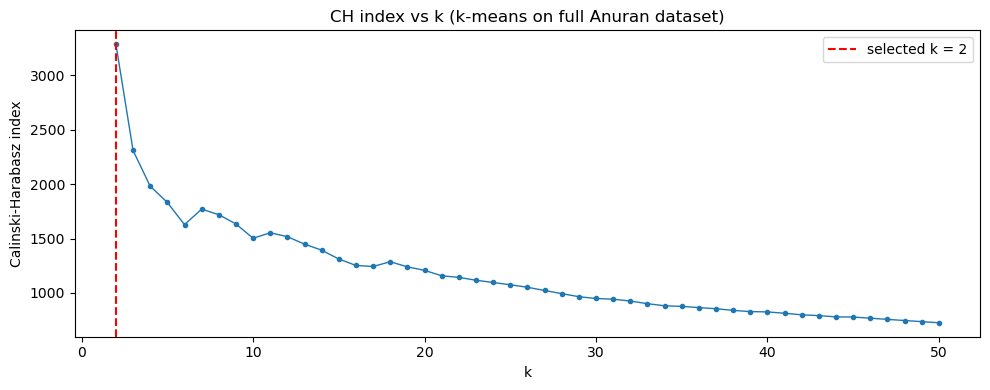


Top-10 k by CH:
  k            CH
  2       3284.61
  3       2309.05
  4       1980.50
  5       1831.45
  7       1770.32
  8       1719.18
  9       1634.03
  6       1627.55
 11       1553.00
 12       1517.17


In [43]:
print("Full dataset:", X.shape)  

X_scaled = StandardScaler().fit_transform(X)

K_VALUES = range(2, 51)

def select_k_ch(X, k_values=K_VALUES, random_state=0, n_init=1):
    """Fit k-means for each k, compute CH, return best k and full scores."""
    ch_scores = {}
    for k in k_values:
        km  = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
        lbl = km.fit_predict(X)
        ch_scores[k] = calinski_harabasz_score(X, lbl)
    best_k = max(ch_scores, key=ch_scores.get)
    return best_k, ch_scores

k_best, ch_scores = select_k_ch(X_scaled, random_state=0)

print(f"\nSelected k (max CH) = {k_best}")
print(f"CH at k_best        = {ch_scores[k_best]:.2f}")
print(f"CH at k=2           = {ch_scores[2]:.2f}")
print(f"CH at k=50          = {ch_scores[50]:.2f}")

plt.figure(figsize=(10, 4))
plt.plot(list(ch_scores.keys()), list(ch_scores.values()),
         marker="o", markersize=3, linewidth=1)
plt.axvline(k_best, color="red", linestyle="--",
            label=f"selected k = {k_best}")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz index")
plt.title("CH index vs k (k-means on full Anuran dataset)")
plt.legend()
plt.tight_layout()
plt.show()

top10 = sorted(ch_scores.items(), key=lambda x: -x[1])[:10]
print("\nTop-10 k by CH:")
print(f"{'k':>3}  {'CH':>12}")
for k, s in top10:
    print(f"{k:>3}  {s:>12.2f}")

K-means was applied to all 7,195 observations using 22 standardized MFCC features and `n_init=1`. The number of clusters was selected by maximizing the Calinski–Harabasz (CH) index:

$$
CH(k)=\frac{B_k/(k-1)}{W_k/(n-k)},
$$

where $B_k$ and $W_k$ are the between-cluster and within-cluster sums of squares, respectively, and $n=7195$.

Since CH is undefined at $k=1$, candidates $k=2,\ldots,50$ were evaluated. The selected value was **$k=2$**, with CH = 3284.61.

### (b) Determine which family is the majority

In [26]:
k = k_best
km = KMeans(n_clusters=k, n_init=1, random_state=0)
cluster_labels = km.fit_predict(X_scaled)

labels_df = y.copy()
labels_df["cluster"] = cluster_labels

print("Cluster sizes:")
print(labels_df["cluster"].value_counts().sort_index(), "\n")

majority_triplets = {}
coverage = {}
for c in range(k):
    subset = labels_df[labels_df["cluster"] == c]
    triplet = {
        "Family":  subset["Family"].mode().iloc[0],
        "Genus":   subset["Genus"].mode().iloc[0],
        "Species": subset["Species"].mode().iloc[0],
    }
    majority_triplets[c] = triplet
    coverage[c] = {
        "Family":  subset["Family"].value_counts(normalize=True).iloc[0],
        "Genus":   subset["Genus"].value_counts(normalize=True).iloc[0],
        "Species": subset["Species"].value_counts(normalize=True).iloc[0],
    }

    print(f"Cluster {c} (n={len(subset)})")
    print(f"  Majority Family  : {triplet['Family']}")
    print(f"  Majority Genus   : {triplet['Genus']}")
    print(f"  Majority Species : {triplet['Species']}")
    print(f"  Coverage: F={coverage[c]['Family']:.3f}, "
          f"G={coverage[c]['Genus']:.3f}, S={coverage[c]['Species']:.3f}")
    print("  Family  distribution (top 3):")
    print(subset["Family"].value_counts(normalize=True).head(3).round(3).to_string())
    print("  Genus   distribution (top 3):")
    print(subset["Genus"].value_counts(normalize=True).head(3).round(3).to_string())
    print("  Species distribution (top 3):")
    print(subset["Species"].value_counts(normalize=True).head(3).round(3).to_string())
    print()

print("Summary of majority triplets:")
print(pd.DataFrame(majority_triplets).T)

Cluster sizes:
cluster
0    3567
1    3628
Name: count, dtype: int64 

Cluster 0 (n=3567)
  Majority Family  : Leptodactylidae
  Majority Genus   : Adenomera
  Majority Species : AdenomeraHylaedactylus
  Coverage: F=0.973, G=0.973, S=0.973
  Family  distribution (top 3):
Family
Leptodactylidae    0.973
Hylidae            0.027
  Genus   distribution (top 3):
Genus
Adenomera        0.973
Dendropsophus    0.019
Hypsiboas        0.005
  Species distribution (top 3):
Species
AdenomeraHylaedactylus    0.973
HylaMinuta                0.019
HypsiboasCordobae         0.005

Cluster 1 (n=3628)
  Majority Family  : Hylidae
  Majority Genus   : Hypsiboas
  Majority Species : HypsiboasCordobae
  Coverage: F=0.570, G=0.434, S=0.304
  Family  distribution (top 3):
Family
Hylidae            0.570
Leptodactylidae    0.262
Dendrobatidae      0.149
  Genus   distribution (top 3):
Genus
Hypsiboas    0.434
Adenomera    0.188
Ameerega     0.149
  Species distribution (top 3):
Species
HypsiboasCordobae     

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [28]:
N_RUNS = 50
LABELS = ["Family", "Genus", "Species"]


def one_mc_run(X, y, seed):
    best_k = None
    best_ch = -np.inf
    best_clusters = None

    for k in range(2, 51):
        km = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=1,
            random_state=seed
        )
        clusters = km.fit_predict(X)
        ch = calinski_harabasz_score(X, clusters)

        if ch > best_ch:
            best_k = k
            best_ch = ch
            best_clusters = clusters.copy()

    pred_df = pd.DataFrame(
        index=y.index,
        columns=LABELS,
        dtype=object
    )

    for c in range(best_k):
        mask = best_clusters == c

        for label in LABELS:
            majority = y.loc[mask, label].mode().iloc[0]
            pred_df.loc[mask, label] = majority

    correct = y[LABELS].eq(pred_df[LABELS]).to_numpy()
    hl = (~correct).mean()

    return {
        "Run": seed + 1,
        "k": best_k,
        "Avg Hamming Distance": (~correct).sum(axis=1).mean(),
        "Hamming Score": 1.0 - hl,
        "Hamming Loss": hl
    }


records = []

with threadpool_limits(limits=1):
    for run in range(N_RUNS):
        result = one_mc_run(X_scaled, y, seed=run)
        records.append(result)

df_mc = pd.DataFrame(records)

print("\nDistribution of selected k across 50 runs:")
print(df_mc["k"].value_counts().sort_index().to_string())

metric_cols = [
    "Avg Hamming Distance",
    "Hamming Score",
    "Hamming Loss"
]

summary = pd.DataFrame({
    "Mean": df_mc[metric_cols].mean(),
    "Std": df_mc[metric_cols].std(ddof=1),
    "Min": df_mc[metric_cols].min(),
    "Max": df_mc[metric_cols].max()
}).round(6)

print("\nSummary over 50 Monte-Carlo runs:")
print(summary.to_string())


Distribution of selected k across 50 runs:
k
2    50

Summary over 50 Monte-Carlo runs:
                          Mean       Std       Min       Max
Avg Hamming Distance  0.894104  0.000047  0.894093  0.894371
Hamming Score         0.701965  0.000016  0.701876  0.701969
Hamming Loss          0.298035  0.000016  0.298031  0.298124


The full procedure was repeated 50 times using different random seeds and `n_init=1`. Each run reselected \(k\) using CH and assigned the majority Family, Genus, and Species labels within each selected cluster.

All 50 runs selected \(k=2\). The average Hamming distance was 0.894104 (SD = 0.000047). The mean Hamming score and Hamming loss were 0.701965 and 0.298035, respectively, both with SD = 0.000016. These small standard deviations indicate stable metrics across the tested seeds.

## 3. ISLR 12.6.2

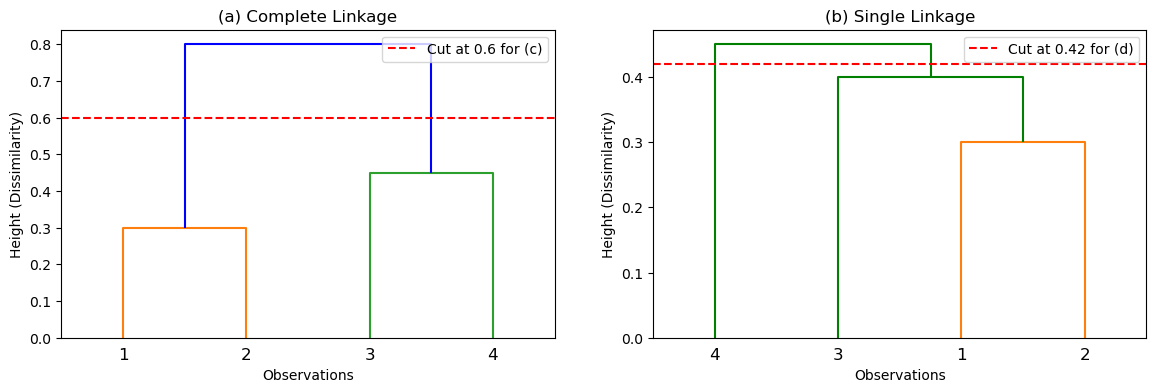

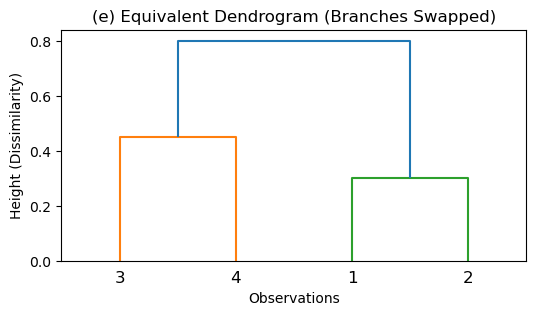

In [92]:
dist_matrix = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00]
])
condensed_dist = squareform(dist_matrix)
labels = ['1', '2', '3', '4']
Z_complete = sch.linkage(condensed_dist, method='complete')
Z_single = sch.linkage(condensed_dist, method='single')
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1) # Plot (a)
sch.dendrogram(Z_complete, labels=labels, above_threshold_color='blue')
plt.title('(a) Complete Linkage')
plt.ylabel('Height (Dissimilarity)')
plt.xlabel('Observations')
plt.axhline(y=0.6, color='red', linestyle='--', label='Cut at 0.6 for (c)')   #（c)
plt.legend()
plt.subplot(1, 2, 2)   # Plot (b) 
sch.dendrogram(Z_single, labels=labels, above_threshold_color='green')
plt.title('(b) Single Linkage')
plt.ylabel('Height (Dissimilarity)')
plt.xlabel('Observations')
plt.axhline(y=0.42, color='red', linestyle='--', label='Cut at 0.42 for (d)')   #(d)
plt.legend()
Z_equiv = np.array([             
    [2, 3, 0.45, 2],  
    [0, 1, 0.30, 2], 
    [4, 5, 0.80, 4]   
])    #（e)
plt.figure(figsize=(6, 3))
sch.dendrogram(Z_equiv, labels=labels)
plt.title('(e) Equivalent Dendrogram (Branches Swapped)')
plt.ylabel('Height (Dissimilarity)')
plt.xlabel('Observations')
plt.show()

***A***.  The distance between two clusters is the maximum distance between their observations.
- Observations 1 and 2 are closest ($d = 0.3$), so they merge at height 0.3.
- Observations 3 and 4 merge next ($d = 0.45$), at height 0.45.
- Clusters $\{1,2\}$ and $\{3,4\}$ merge at height:

$$
\max(0.4, 0.7, 0.5, 0.8) = 0.8.
$$

Plot (a) visualizes this process.

***B***.The distance between two clusters is the minimum distance between their observations.

- Observations 1 and 2 merge at height 0.3.
- Cluster $\{1,2\}$ merges with Observation 3 at height:

$$
\min(0.4, 0.5) = 0.4.
$$

- Cluster $\{1,2,3\}$ merges with Observation 4 at height:

$$
\min(0.7, 0.8, 0.45) = 0.45.
$$

Plot (b) visualizes this process.

***C***.The complete-linkage fusion heights are 0.3, 0.45, and 0.8. To obtain two clusters, cut horizontally between 0.45 and 0.8, for example at height 0.6.

Result:
- Cluster 1: $\{\text{Obs 1}, \text{Obs 2}\}$.
- Cluster 2: $\{\text{Obs 3}, \text{Obs 4}\}$.

***D***.The single-linkage fusion heights are 0.3, 0.4, and 0.45. To obtain two clusters, cut horizontally between 0.4 and 0.45, for example at height 0.42.

Result:

- Cluster 1: $\{\text{Obs 1}, \text{Obs 2}, \text{Obs 3}\}$.
- Cluster 2: $\{\text{Obs 4}\}$.

Observation 4 remains a singleton at this cut height and joins the other cluster at height 0.45.

***E***.An equivalent dendrogram can be obtained by swapping the left and right branches of the complete-linkage dendrogram in (a):

- Place cluster $\{3,4\}$ on the left, merging at height 0.45.
- Place cluster $\{1,2\}$ on the right, merging at height 0.3.
- Join the two clusters at height 0.8.
  
The leaf order changes, but the cluster memberships and fusion heights remain the same.